# Battery spatial scan: LRN fit versus ground truth

Compare the eight materials and 40 electrode disks from `generate_spatial_scan_more.py` against **only** `E:/Test_data/Batt/LRN_ad/ref_lrn.anra`. Raster names and coordinates come directly from the fit; no spectra or other fit files are required. This notebook reads results and does not run a simulator or refit data.

Run cells in order from within the repository. Requires Python 3.11+, numpy, scipy, matplotlib, and the local ibeamlab package. Tables, figures and provenance are written to `examples/datasets/Batt/LRN_comparison`.

Ground truth assumes the current generator is the one used for this dataset. The notebook checks the complete 100×160 coordinate grid, electrode geometry and element schema, and records file hashes. These checks cannot verify the original chemical model without the generation metadata.


In [10]:
from pathlib import Path
from collections import Counter
import csv
import hashlib
import importlib
import json
import re
import sys
import tomllib

import numpy as np
from scipy.special import erf
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "examples/generate_spatial_scan_more.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from within the iBeamLab repository")
sys.path.insert(0, str(ROOT / "examples"))
import generate_spatial_scan_more as scan
scan = importlib.reload(scan)

FIT_PATH = Path("E:/Test_data/Batt/LRN_ad/ref_lrn.anra")
OUT = ROOT / "examples/datasets/Batt/LRN_comparison"
COMPARISON_DEPTH = 100_000.0
TMAX = scan.MAX_DEPTH
DEPTH_STEP = 100.0
HEATMAP_DEPTH = 0.0
EXTEND_LAST = True
OUT.mkdir(parents=True, exist_ok=True)

def write_csv(name, rows):
    if not rows:
        raise ValueError(f"No rows for {name}")
    with (OUT / name).open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def table(rows, columns):
    def fmt(v):
        return f"{v:.4g}" if isinstance(v, (float, np.floating)) else str(v)
    lines = ["| " + " | ".join(columns) + " |", "|" + "---|"*len(columns)]
    lines += ["| " + " | ".join(fmt(r[k]) for k in columns) + " |" for r in rows]
    text = "\n".join(lines)
    try:
        from IPython.display import display, HTML
        from html import escape
        html = '<div style="max-height:500px;overflow:auto"><table>'
        html += '<tr>' + ''.join('<th style="padding:6px">'+escape(k)+'</th>' for k in columns) + '</tr>'
        for r in rows:
            html += '<tr>' + ''.join('<td style="padding:6px;text-align:right">'+escape(fmt(r[k]))+'</td>' for k in columns) + '</tr>'
        display(HTML(html + '</table></div>'))
    except ImportError:
        print(text)

def finish(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()

def error_metrics(values):
    values = np.asarray(values, float)
    finite = np.isfinite(values)
    a = values[finite]
    return dict(mae_pp=float(np.mean(abs(a))) if len(a) else np.nan,
                rmse_pp=float(np.sqrt(np.mean(a*a))) if len(a) else np.nan,
                bias_pp=float(np.mean(a)) if len(a) else np.nan,
                valid_count=int(finite.sum()), undefined_count=int((~finite).sum()))

print("LRN fit:", FIT_PATH)
print("Output:", OUT)


LRN fit: E:\Test_data\Batt\LRN_ad\ref_lrn.anra
Output: d:\ibeamlab\examples\datasets\Batt\LRN_comparison


## Reconstruct AutoNRA profiles

Use the same degree-zero Erf reconstruction as `compare_spatial_scan_soc.ipynb`: `abs(A*(1+a*erf((u-b)/c)))`, normalized over **all fitted elements at each sublayer midpoint**. Read the number of sublayers and linear/log spacing from this fit's configuration; do not assume five sublayers. Log edges reproduce the original notebook's AutoNRA convention. The c=0 limit is handled explicitly.

Full-thickness inventories integrate atomic fraction × actual fitted areal thickness. Invalid profiles, duplicate results, unsupported parameterizations and incomplete rasters stop the calculation. Fit statuses and chi-squared values remain available for diagnostics.


In [11]:
def read_fit(path):
    with path.open("rb") as f:
        doc = tomllib.load(f)
    config = doc["Config"]
    layer = config["Layers"]
    if (layer["NumberOfLayers"] != 1 or layer["Parameterization"] != ["Erf-polynomial"]
            or layer["Parameterization_Degree"] != [0]):
        raise ValueError("This reconstruction supports one degree-zero Erf-polynomial layer")
    n = int(layer["N_sublayers"][0])
    if n < 1:
        raise ValueError("N_sublayers must be positive")
    scaling = layer["Discretization_scaling"][0]
    if scaling == "Log":
        edges = 4.0**np.linspace(-3, 0, n+1)
        offset = edges[0]
        edges -= offset
        edges[-1] += offset
    elif scaling == "Linear":
        edges = np.linspace(0, 1, n+1)
    else:
        raise ValueError(f"Unsupported discretization: {scaling}")
    mids, weights = (edges[:-1]+edges[1:])/2, np.diff(edges)
    elements = tuple(s.split(":")[0].strip() for s in layer["ElementsPerLayer"][0].split(","))
    if len(set(elements)) != len(elements):
        raise ValueError("Duplicate fitted elements")
    defaults = {p[0]: p[1] for p in config["Analysis"]["Parameters"]}
    bases = {}
    for element in elements:
        matches = [k[:-2] for k in defaults if re.fullmatch(r"Erf_1_\s*"+re.escape(element)+"_A", k)]
        if len(matches) != 1:
            raise ValueError(f"Missing or ambiguous parameters for {element}")
        bases[element] = matches[0]
    fits = {}
    for result in doc["BatchResults"]:
        name = result["Sample"]
        if name in fits:
            raise ValueError(f"Duplicate sample: {name}")
        p = defaults | result["Parameters"]
        profiles = []
        for element in elements:
            key = bases[element]
            A, a, b, c = (float(p[key+suffix]) for suffix in ("_A", "_a", "_b", "_c"))
            if not np.isfinite([A, a, b, c]).all():
                raise ValueError(f"Nonfinite parameters: {name}, {element}")
            mode = erf((mids-b)/c) if c != 0 else np.sign(mids-b)
            profiles.append(np.abs(A*(1+a*mode)))
        f = np.array(profiles).T
        totals = f.sum(axis=1, keepdims=True)
        if not np.isfinite(f).all() or np.any(totals <= 0):
            raise ValueError(f"Invalid normalization: {name}")
        f /= totals
        thickness = float(p["Thickness_1"])
        if not np.isfinite(thickness) or thickness <= 0:
            raise ValueError(f"Invalid thickness: {name}")
        fits[name] = dict(edges=edges*thickness, fractions=f,
                          inventory=weights@f*thickness,
                          status=result["Status"], chi2=result.get("Chi2", np.nan))
    return doc, elements, fits

def soc_from_inventory(inventory, chem):
    # Formula-unit count estimated from this chemistry's expected host atoms.
    host = sum(inventory[elements.index(e)] for e in chem.host)
    if not np.isfinite(host) or host <= 0:
        return np.nan
    x = chem.host_atoms * inventory[elements.index(chem.mobile_ion)] / host
    t = (x-chem.x_min)/(chem.x_max-chem.x_min)
    return t if chem.electrode == "anode" else 1-t

def integrate_stack(edges, fractions, depth):
    if not np.isfinite(depth) or depth <= 0:
        raise ValueError("Depth must be finite and positive")
    widths = np.maximum(0, np.minimum(edges[1:], depth)-edges[:-1])
    result = widths@fractions
    if depth > edges[-1]:
        result += (depth-edges[-1])*fractions[-1]
    np.testing.assert_allclose(result.sum(), depth, rtol=1e-10)
    return result

def sample_stack(edges, fractions, depths):
    depths = np.asarray(depths, float)
    index = np.minimum(np.searchsorted(edges[1:], depths, side="right"), len(fractions)-1)
    return fractions[index]

np.testing.assert_allclose(integrate_stack(np.array([0,20,50]), np.array([[.1,.9],[.2,.8]]), 30), [4,26])
np.testing.assert_allclose(integrate_stack(np.array([0,20,50]), np.array([[.1,.9],[.2,.8]]), 60), [10,50])
np.testing.assert_allclose(sample_stack(np.array([0,20,50]), np.array([[.1],[.2]]), [0,19,20,50,100]).ravel(), [.1,.1,.2,.2,.2])


## Load the fit and validate its raster

Positions are parsed from `Sample` names, including signed nanometre coordinates and both angles. The expected grid is 100 columns × 160 rows. Use rounded nanometre coordinates, matching the generator's filenames. All points, including Al holder points, are retained for element maps; only electrode points contribute to SOC metrics.


In [12]:
doc, fit_elements, fits = read_fit(FIT_PATH)
elements = tuple(dict.fromkeys((*scan.ARRAY_ELEMENTS, *fit_elements)))
missing = set(scan.ARRAY_ELEMENTS)-set(fit_elements)
if missing:
    raise ValueError(f"Missing fitted elements: {sorted(missing)}")
for result in fits.values():
    aligned = np.zeros((len(result["fractions"]), len(elements)))
    for j, e in enumerate(fit_elements):
        aligned[:, elements.index(e)] = result["fractions"][:, j]
    result["fractions"] = aligned
    result["inventory"] = np.diff(result["edges"])@aligned

names = sorted(fits)
pattern = re.compile(r"^(.+)_(-?\d+)_(-?\d+)_(-?\d+)_(-?\d+)$")
coords_nm = []
prefixes = set()
for name in names:
    m = pattern.fullmatch(name)
    if m is None:
        raise ValueError(f"Cannot parse coordinates: {name}")
    prefix, x, theta1, y, theta2 = m.groups()
    if (int(theta1), int(theta2)) != (scan.THETA1, scan.THETA2):
        raise ValueError(f"Unexpected angles: {name}")
    coords_nm.append((int(x), int(y)))
    prefixes.add(prefix)
coords_nm = np.asarray(coords_nm, dtype=np.int64)
gx, gy = scan.array_scan_grid()
expected = set(zip(np.rint(gx.ravel()*1e6).astype(np.int64), np.rint(gy.ravel()*1e6).astype(np.int64)))
actual = set(map(tuple, coords_nm))
if len(prefixes) != 1 or len(actual) != len(names) or actual != expected:
    raise ValueError(f"Raster mismatch: {len(actual)} unique positions; missing {len(expected-actual)}, extra {len(actual-expected)}")
configured_names = doc["Config"]["Analysis"]["Sample_list"]
if len(set(configured_names)) != len(configured_names) or set(configured_names) != set(names):
    raise ValueError("Configured sample list and results differ")
if doc["Config"]["Analysis"]["Number_of_samples"] != len(names):
    raise ValueError("Configured sample count differs from results")
status_counts = Counter(r["status"] for r in fits.values())
print("Statuses:", dict(status_counts))
if set(status_counts) != {"Finished"}:
    raise ValueError("Review unfinished fit results before comparing")

xy = coords_nm/1e6
cell_ids = scan._array_cell_ids(xy[:,0], xy[:,1])
cells = scan.array_cell_layout()
thicknesses = scan.sublayer_thicknesses()
truth_edges = np.r_[0, np.cumsum(thicknesses)]
truth_native = scan.array_composition(xy[:,0,None], xy[:,1,None],
                                     ((truth_edges[:-1]+truth_edges[1:])/2)[None,:])
truth_stacks = np.zeros((len(names), len(thicknesses), len(elements)))
for j, element in enumerate(scan.ARRAY_ELEMENTS):
    truth_stacks[:,:,elements.index(element)] = truth_native[:,:,j]
truth_inventory = np.einsum("l,nle->ne", thicknesses, truth_stacks)
fit_inventory = np.array([fits[name]["inventory"] for name in names])
np.testing.assert_allclose(truth_stacks.sum(axis=2), 1, atol=1e-12)
np.testing.assert_allclose(truth_inventory.sum(axis=1), scan.MAX_DEPTH)
groups = {c["cell_id"]: np.flatnonzero(cell_ids == c["cell_id"]) for c in cells}
if any(len(indices) == 0 for indices in groups.values()):
    raise ValueError("At least one electrode disk is unsampled")

generator_path = ROOT / "examples/generate_spatial_scan_more.py"
provenance = dict(fit_path=str(FIT_PATH), fit_sha256=hashlib.sha256(FIT_PATH.read_bytes()).hexdigest(),
    generator_path=str(generator_path), generator_sha256=hashlib.sha256(generator_path.read_bytes()).hexdigest(),
    expected_grid_columns=int(gx.shape[1]), expected_grid_rows=int(gx.shape[0]),
    fitted_sublayers=doc["Config"]["Layers"]["N_sublayers"][0], status_counts=dict(status_counts),
    elements=elements, ground_truth_assumption="Current generator matches data; no original generation metadata supplied",
    chemistries=[dict(name=c.name, mobile_ion=c.mobile_ion, host=c.host, x_min=c.x_min,
                     x_max=c.x_max, basis=c.basis) for c in scan.CHEMISTRIES])
(OUT / "input_provenance.json").write_text(json.dumps(provenance, indent=2)+"\n", encoding="utf-8")
print(f"Validated {len(names):,} positions: {gx.shape[1]} x {gx.shape[0]}; "
      f"{np.sum(cell_ids >= 0):,} electrode and {np.sum(cell_ids < 0):,} holder positions")
print("Fitted sublayers:", provenance["fitted_sublayers"])


Statuses: {'Finished': 16000}
Validated 16,000 positions: 100 x 160; 9,940 electrode and 6,060 holder positions
Fitted sublayers: 7


## Material-specific SOC from pooled inventories

Let H be the number of non-mobile atoms in the material's host formula. Estimate `x = H × I_mobile / sum(I_expected_host)` from integrated inventories, then map x to the generator's material-specific bounds. Anodes gain Li/Na on charging; cathodes lose it. Host elemental ratios are assumed to follow the material's formula. Unexpected elements are excluded from the SOC host denominator, but retained in total atomic fractions and reported separately.

Pool inventories across each disk **before** computing its SOC. The finite raster's truth can differ slightly from nominal SOC. Errors use the raster truth. SOC is never clipped; zero host inventory gives NaN. Large errors and out-of-range predictions remain visible. A local SOC here integrates one pixel over its full depth; it is not the surface SOC.


In [13]:
position_rows, cell_rows = [], []
truth_soc = np.full(len(names), np.nan)
fit_soc = np.full(len(names), np.nan)
for cell in cells:
    chem = scan.CHEMISTRY_BY_NAME[cell["chemistry"]]
    indices = groups[cell["cell_id"]]
    allowed = {chem.mobile_ion, *chem.host}
    unexpected = [j for j,e in enumerate(elements) if e not in allowed]
    for i in indices:
        truth_soc[i] = 100*soc_from_inventory(truth_inventory[i], chem)
        fit_soc[i] = 100*soc_from_inventory(fit_inventory[i], chem)
        position_rows.append(dict(sample=names[i], cell_id=cell["cell_id"], chemistry=chem.name,
            mobile_ion=chem.mobile_ion, x_mm=xy[i,0], y_mm=xy[i,1], nominal_soc_pct=100*cell["soc"],
            truth_soc_pct=truth_soc[i], LRN_soc_pct=fit_soc[i], error_pp=fit_soc[i]-truth_soc[i],
            chi2=fits[names[i]]["chi2"], status=fits[names[i]]["status"],
            LRN_unexpected_atomic_pct=100*fit_inventory[i,unexpected].sum()/fit_inventory[i].sum()))
    t, f = truth_inventory[indices].sum(axis=0), fit_inventory[indices].sum(axis=0)
    t_soc, f_soc = 100*soc_from_inventory(t,chem), 100*soc_from_inventory(f,chem)
    pixel_errors = fit_soc[indices]-truth_soc[indices]
    cell_rows.append(dict(cell_id=cell["cell_id"], chemistry=chem.name, mobile_ion=chem.mobile_ion,
        column=cell["column"]+1, n_positions=len(indices), nominal_soc_pct=100*cell["soc"],
        truth_soc_pct=t_soc, LRN_soc_pct=f_soc, error_pp=f_soc-t_soc,
        pixel_rmse_pp=error_metrics(pixel_errors)["rmse_pp"],
        undefined_positions=int(np.sum(~np.isfinite(fit_soc[indices]))),
        outside_range_positions=int(np.sum(np.isfinite(fit_soc[indices]) & ((fit_soc[indices]<0)|(fit_soc[indices]>100)))),
        LRN_unexpected_atomic_pct=100*f[unexpected].sum()/f.sum()))
write_csv("position_soc.csv", position_rows)
write_csv("cell_soc.csv", cell_rows)
table(cell_rows, ["chemistry","column","n_positions","nominal_soc_pct","truth_soc_pct","LRN_soc_pct","error_pp","pixel_rmse_pp"])

metrics = []
for scope in ("all", *(c.name for c in scan.CHEMISTRIES)):
    cr = [r for r in cell_rows if scope == "all" or r["chemistry"] == scope]
    pr = [r for r in position_rows if scope == "all" or r["chemistry"] == scope]
    metrics.append(dict(scope=scope, level="cell", **error_metrics([r["error_pp"] for r in cr])))
    metrics.append(dict(scope=scope, level="position", **error_metrics([r["error_pp"] for r in pr])))
write_csv("soc_metrics.csv", metrics)
(OUT / "soc_metrics.json").write_text(json.dumps(metrics, indent=2)+"\n", encoding="utf-8")
table(metrics, ["scope","level","mae_pp","rmse_pp","bias_pp","valid_count","undefined_count"])


chemistry,column,n_positions,nominal_soc_pct,truth_soc_pct,LRN_soc_pct,error_pp,pixel_rmse_pp
NMC111,1,250,0,-1.998e-13,-0.7544,-0.7544,1.352
NMC111,2,247,25,24.96,24.5,-0.4664,1.172
NMC111,3,250,50,50.11,48.39,-1.724,2.296
NMC111,4,247,75,74.96,74.01,-0.9499,25.13
NMC111,5,250,100,100,101.5,1.522,1.625
LFP,1,250,0,0,-4.826,-4.826,5.296
LFP,2,249,25,25.03,20.95,-4.083,4.453
LFP,3,252,50,50.16,47.81,-2.351,2.772
LFP,4,249,75,75.02,75.1,0.08499,0.4567
LFP,5,250,100,100,101.7,1.684,1.696


scope,level,mae_pp,rmse_pp,bias_pp,valid_count,undefined_count
all,cell,2.512,5.001,-1.204,40,0
all,position,2.977,12.89,-1.303,9940,0
NMC111,cell,1.083,1.181,-0.4746,5,0
NMC111,position,1.573,11.3,-0.7338,1244,0
LFP,cell,2.606,3.109,-1.898,5,0
LFP,position,2.689,3.424,-1.928,1250,0
LMO,cell,1.397,1.554,1.33,5,0
LMO,position,1.46,1.695,1.327,1224,0
Sodium NFM,cell,11.32,13.31,-8.982,5,0
Sodium NFM,position,13.72,33.96,-9.764,1252,0


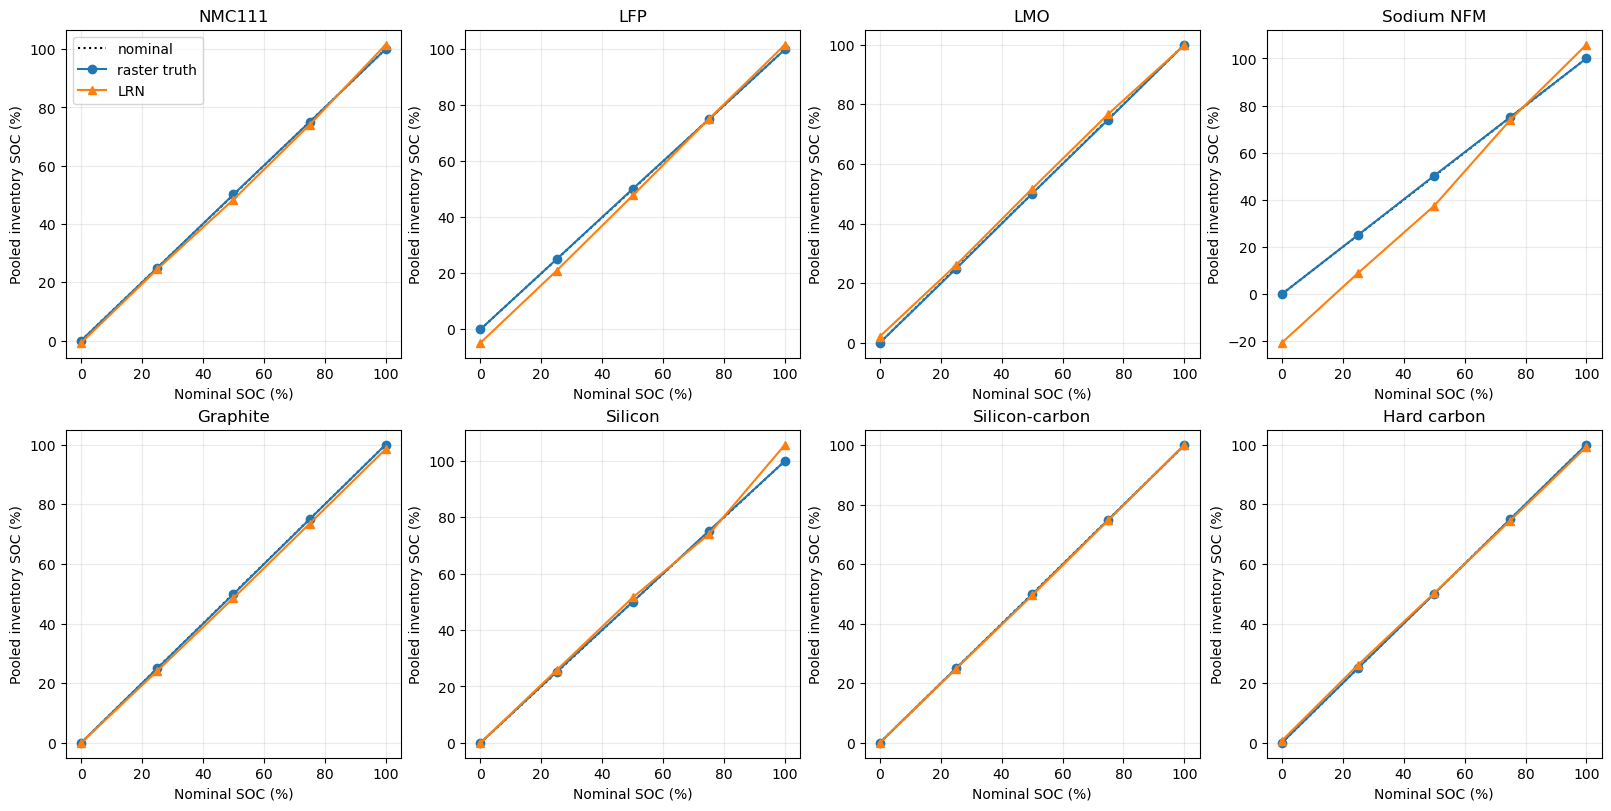

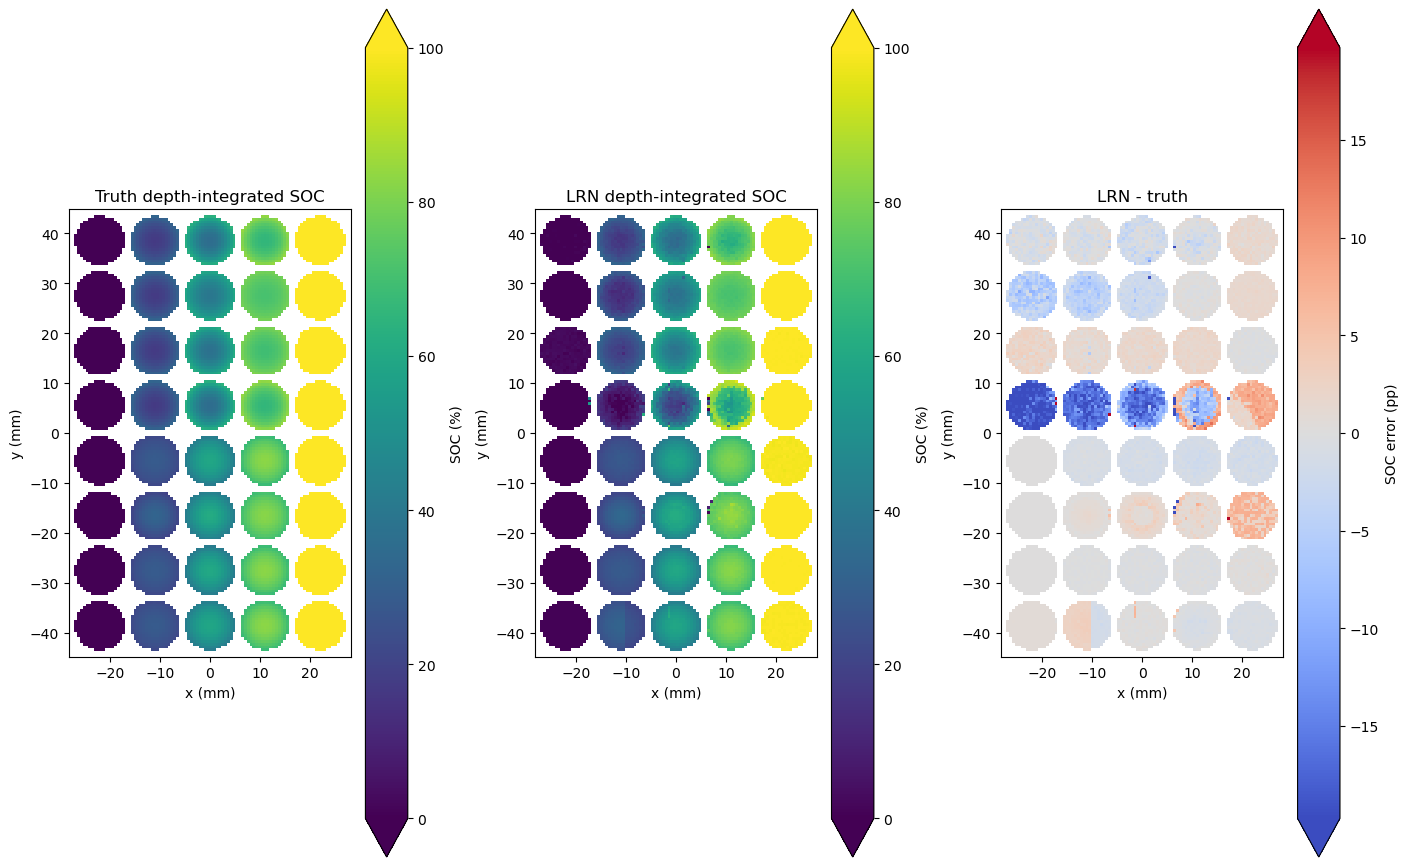

SOC maps use display limits 0-100%; error scale uses the 98th absolute percentile.
Exported SOC values and metrics are not clipped.


In [14]:
fig, axes = plt.subplots(2,4,figsize=(16,8),constrained_layout=True)
for ax, chem in zip(axes.flat, scan.CHEMISTRIES):
    selected = [r for r in cell_rows if r["chemistry"] == chem.name]
    xx = [r["nominal_soc_pct"] for r in selected]
    ax.plot(xx, xx, "k:", label="nominal")
    ax.plot(xx, [r["truth_soc_pct"] for r in selected], "o-", label="raster truth")
    ax.plot(xx, [r["LRN_soc_pct"] for r in selected], "^-", label="LRN")
    ax.set(title=chem.name, xlabel="Nominal SOC (%)", ylabel="Pooled inventory SOC (%)")
    ax.grid(alpha=.25)
axes.flat[0].legend()
finish(fig, "cell_soc_comparison")

x_axis, y_axis = np.unique(xy[:,0]), np.unique(xy[:,1])
ix, iy = np.searchsorted(x_axis,xy[:,0]), np.searchsorted(y_axis,xy[:,1])
def image_grid(values):
    a = np.full((len(y_axis),len(x_axis)), np.nan)
    a[iy,ix] = values
    return a
def spatial_image(ax, values, title, cmap="viridis", vmin=None, vmax=None):
    m = ax.pcolormesh(x_axis,y_axis,image_grid(values),shading="auto",cmap=cmap,vmin=vmin,vmax=vmax)
    ax.set(title=title,aspect="equal",xlabel="x (mm)",ylabel="y (mm)")
    return m

finite_errors = (fit_soc-truth_soc)[np.isfinite(fit_soc-truth_soc)]
error_limit = max(float(np.percentile(abs(finite_errors),98)),1) if len(finite_errors) else 1
fig, axes = plt.subplots(1,3,figsize=(14,9),constrained_layout=True)
for ax, values, title in zip(axes[:2], (truth_soc,fit_soc), ("Truth depth-integrated SOC", "LRN depth-integrated SOC")):
    m = spatial_image(ax,values,title,vmin=0,vmax=100)
    fig.colorbar(m,ax=ax,label="SOC (%)",extend="both")
m = spatial_image(axes[2],fit_soc-truth_soc,"LRN - truth",cmap="coolwarm",vmin=-error_limit,vmax=error_limit)
fig.colorbar(m,ax=axes[2],label="SOC error (pp)",extend="both")
finish(fig,"spatial_soc_comparison")
print("SOC maps use display limits 0-100%; error scale uses the 98th absolute percentile.")
print("Exported SOC values and metrics are not clipped.")


## Element recovery across all eight materials

Pool full-thickness inventories per disk and normalize over every fitted element, including unexpected species. Compare all eleven elements, including absent-species leakage. Cell errors can cancel local errors, so per-position RMSE is reported separately. Host ratios are not forced to the expected formula in the fit.


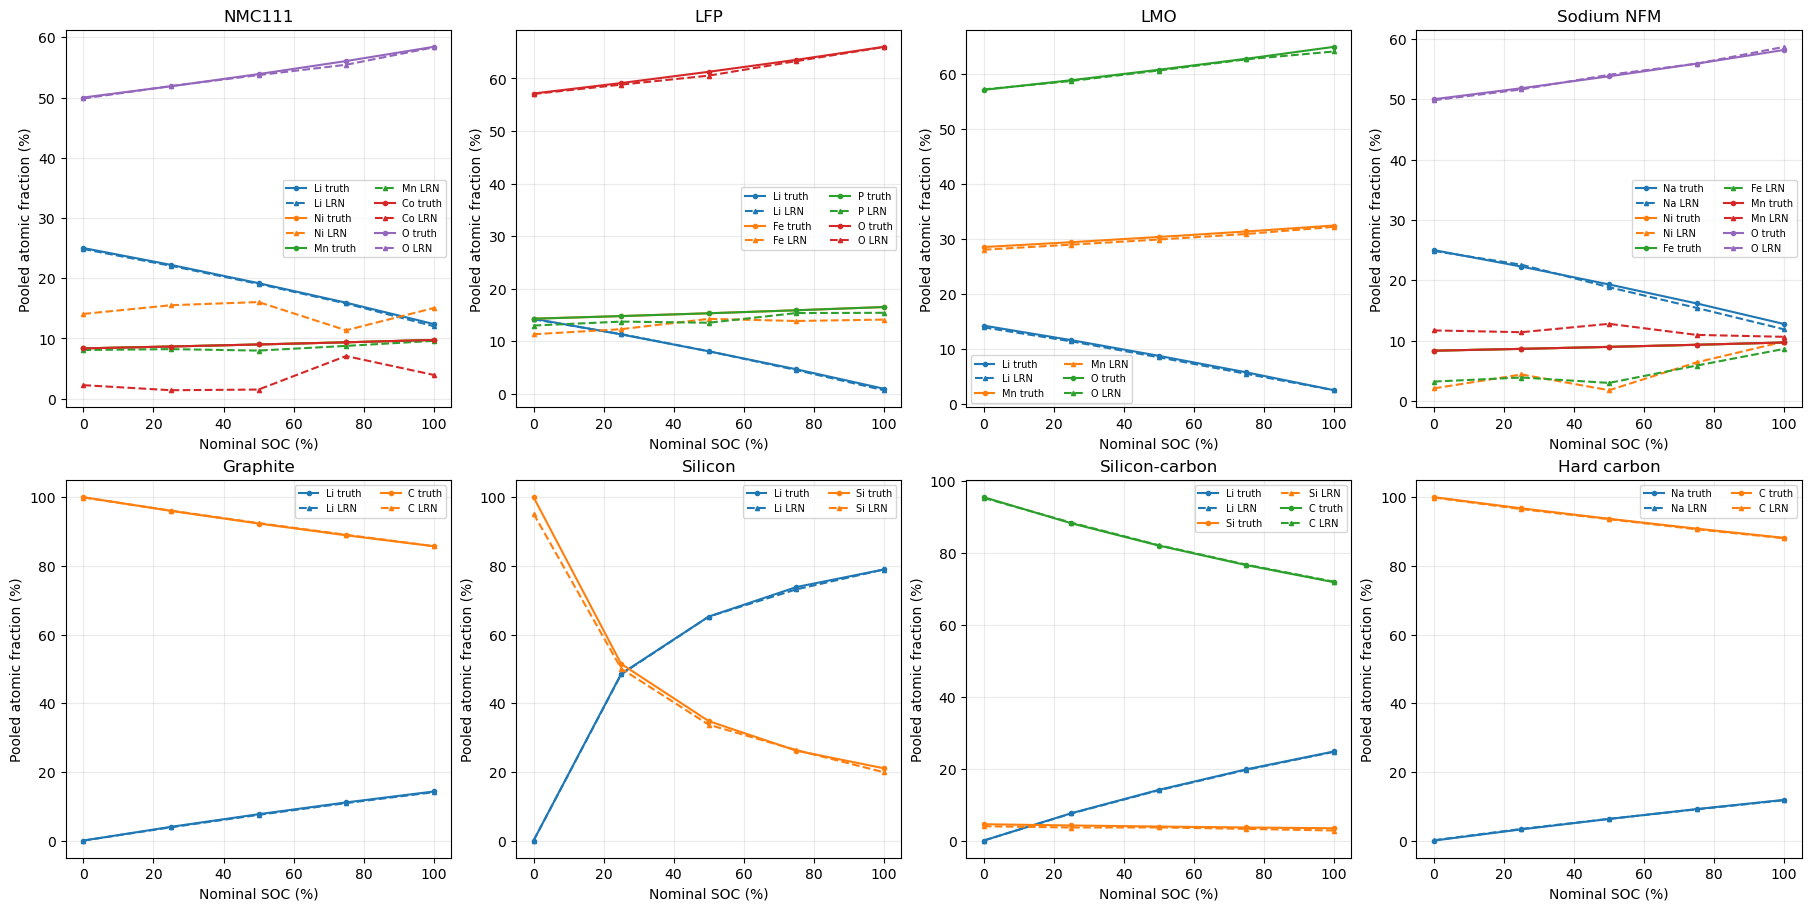

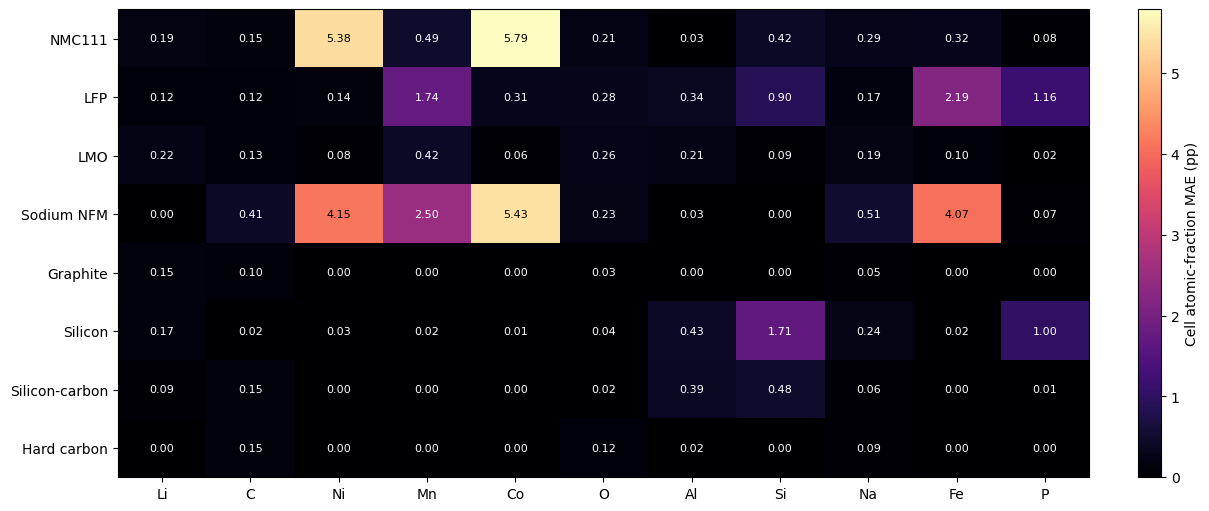

In [15]:
composition_rows, element_metrics = [], []
truth_atomic = truth_inventory/truth_inventory.sum(axis=1,keepdims=True)
fit_atomic = fit_inventory/fit_inventory.sum(axis=1,keepdims=True)
for cell in cells:
    indices = groups[cell["cell_id"]]
    t, f = truth_inventory[indices].sum(axis=0), fit_inventory[indices].sum(axis=0)
    for j, element in enumerate(elements):
        composition_rows.append(dict(cell_id=cell["cell_id"],chemistry=cell["chemistry"],
            column=cell["column"]+1,nominal_soc_pct=100*cell["soc"],element=element,
            truth_atomic_pct=100*t[j]/t.sum(),LRN_atomic_pct=100*f[j]/f.sum(),
            error_pp=100*(f[j]/f.sum()-t[j]/t.sum())))
for chem in scan.CHEMISTRIES:
    selected_positions = np.flatnonzero(np.isin(cell_ids,[c["cell_id"] for c in cells if c["chemistry"]==chem.name]))
    for j, element in enumerate(elements):
        selected = [r for r in composition_rows if r["chemistry"]==chem.name and r["element"]==element]
        em = error_metrics([r["error_pp"] for r in selected])
        pixel = error_metrics(100*(fit_atomic[selected_positions,j]-truth_atomic[selected_positions,j]))
        element_metrics.append(dict(chemistry=chem.name,element=element,cell_mae_pp=em["mae_pp"],
            cell_rmse_pp=em["rmse_pp"],cell_bias_pp=em["bias_pp"],pixel_rmse_pp=pixel["rmse_pp"]))
write_csv("cell_element_fractions.csv",composition_rows)
write_csv("element_recovery_metrics.csv",element_metrics)
np.savez_compressed(OUT/"position_element_fractions.npz",sample=np.array(names),xy_mm=xy,
    cell_id=cell_ids,elements=np.array(elements),truth_atomic_fraction=truth_atomic,LRN_atomic_fraction=fit_atomic)

fig, axes = plt.subplots(2,4,figsize=(18,9),constrained_layout=True)
for ax, chem in zip(axes.flat,scan.CHEMISTRIES):
    relevant = (chem.mobile_ion,*chem.host)
    colors = plt.get_cmap("tab10")
    for j,element in enumerate(relevant):
        selected = [r for r in composition_rows if r["chemistry"]==chem.name and r["element"]==element]
        xx = [r["nominal_soc_pct"] for r in selected]
        ax.plot(xx,[r["truth_atomic_pct"] for r in selected],"o-",color=colors(j),label=element+" truth",ms=3)
        ax.plot(xx,[r["LRN_atomic_pct"] for r in selected],"^--",color=colors(j),label=element+" LRN",ms=3)
    ax.set(title=chem.name,xlabel="Nominal SOC (%)",ylabel="Pooled atomic fraction (%)")
    ax.grid(alpha=.25)
    ax.legend(fontsize=7,ncol=2)
finish(fig,"element_atomic_fractions")

matrix = np.array([[next(r["cell_mae_pp"] for r in element_metrics if r["chemistry"]==c.name and r["element"]==e)
                    for e in elements] for c in scan.CHEMISTRIES])
fig, ax = plt.subplots(figsize=(12,5),constrained_layout=True)
m=ax.imshow(matrix,aspect="auto",cmap="magma",vmin=0)
ax.set_xticks(range(len(elements)),elements)
ax.set_yticks(range(8),[c.name for c in scan.CHEMISTRIES])
for i in range(8):
    for j in range(len(elements)):
        ax.text(j,i,f"{matrix[i,j]:.2f}",ha="center",va="center",fontsize=8,
                color="black" if matrix[i,j] > matrix.max()*.65 else "white")
fig.colorbar(m,ax=ax,label="Cell atomic-fraction MAE (pp)")
finish(fig,"element_recovery_errors")


## Common depth-window sensitivity

Integrate the actual piecewise-constant stacks exactly over 0–10,000, 0–100,000 and `COMPARISON_DEPTH` in 10¹⁵ atoms/cm². Partial layers use their overlap thickness. If a fit ends early, its final-layer fraction is extended; thicker fits are truncated. These comparisons use equal physical areal-depth windows. Surface-window SOC describes that window's composition and need not match nominal whole-disk SOC.


In [16]:
WINDOW_DEPTHS = sorted(set((10_000.0,100_000.0,float(COMPARISON_DEPTH))))
window_rows, window_soc_rows = [], []
for cell in cells:
    indices = groups[cell["cell_id"]]
    chem = scan.CHEMISTRY_BY_NAME[cell["chemistry"]]
    for depth in WINDOW_DEPTHS:
        pooled = {"truth":np.zeros(len(elements)),"LRN":np.zeros(len(elements))}
        extended = 0
        for i in indices:
            result=fits[names[i]]
            pooled["truth"] += integrate_stack(truth_edges,truth_stacks[i],depth)
            pooled["LRN"] += integrate_stack(result["edges"],result["fractions"],depth)
            extended += depth > result["edges"][-1]
        base=dict(cell_id=cell["cell_id"],chemistry=chem.name,nominal_soc_pct=100*cell["soc"],
                  depth_limit=depth,extrapolated_positions=extended)
        t,f=pooled["truth"],pooled["LRN"]
        ts,fs=100*soc_from_inventory(t,chem),100*soc_from_inventory(f,chem)
        window_soc_rows.append(dict(base,truth_soc_pct=ts,LRN_soc_pct=fs,error_pp=fs-ts))
        for j,element in enumerate(elements):
            window_rows.append(dict(base,element=element,truth_atomic_pct=100*t[j]/t.sum(),
                LRN_atomic_pct=100*f[j]/f.sum(),error_pp=100*(f[j]/f.sum()-t[j]/t.sum())))
write_csv("depth_window_cell_fractions.csv",window_rows)
write_csv("depth_window_cell_soc.csv",window_soc_rows)
table([dict(depth_limit=d,**error_metrics([r["error_pp"] for r in window_soc_rows if r["depth_limit"]==d]))
       for d in WINDOW_DEPTHS],["depth_limit","mae_pp","rmse_pp","bias_pp","valid_count","undefined_count"])


depth_limit,mae_pp,rmse_pp,bias_pp,valid_count,undefined_count
1e+04,2.891,5.717,-1.389,40,0
1e+05,2.512,5.001,-1.204,40,0


## Laterally averaged Li/Na depth profiles: all 40 disks

Plot Li for lithium materials and Na for sodium materials. At every common absolute depth, average the reconstructed atomic fractions over equal-area raster positions. Use generator sublayer midpoint fractions for truth and configured AutoNRA sublayers for LRN. Extend the last layer to `TMAX` if necessary and report the fraction of extended positions. These plotted extensions do not change the earlier full-thickness inventory calculations. Shared y limits within each material row allow comparison across its five SOC values.


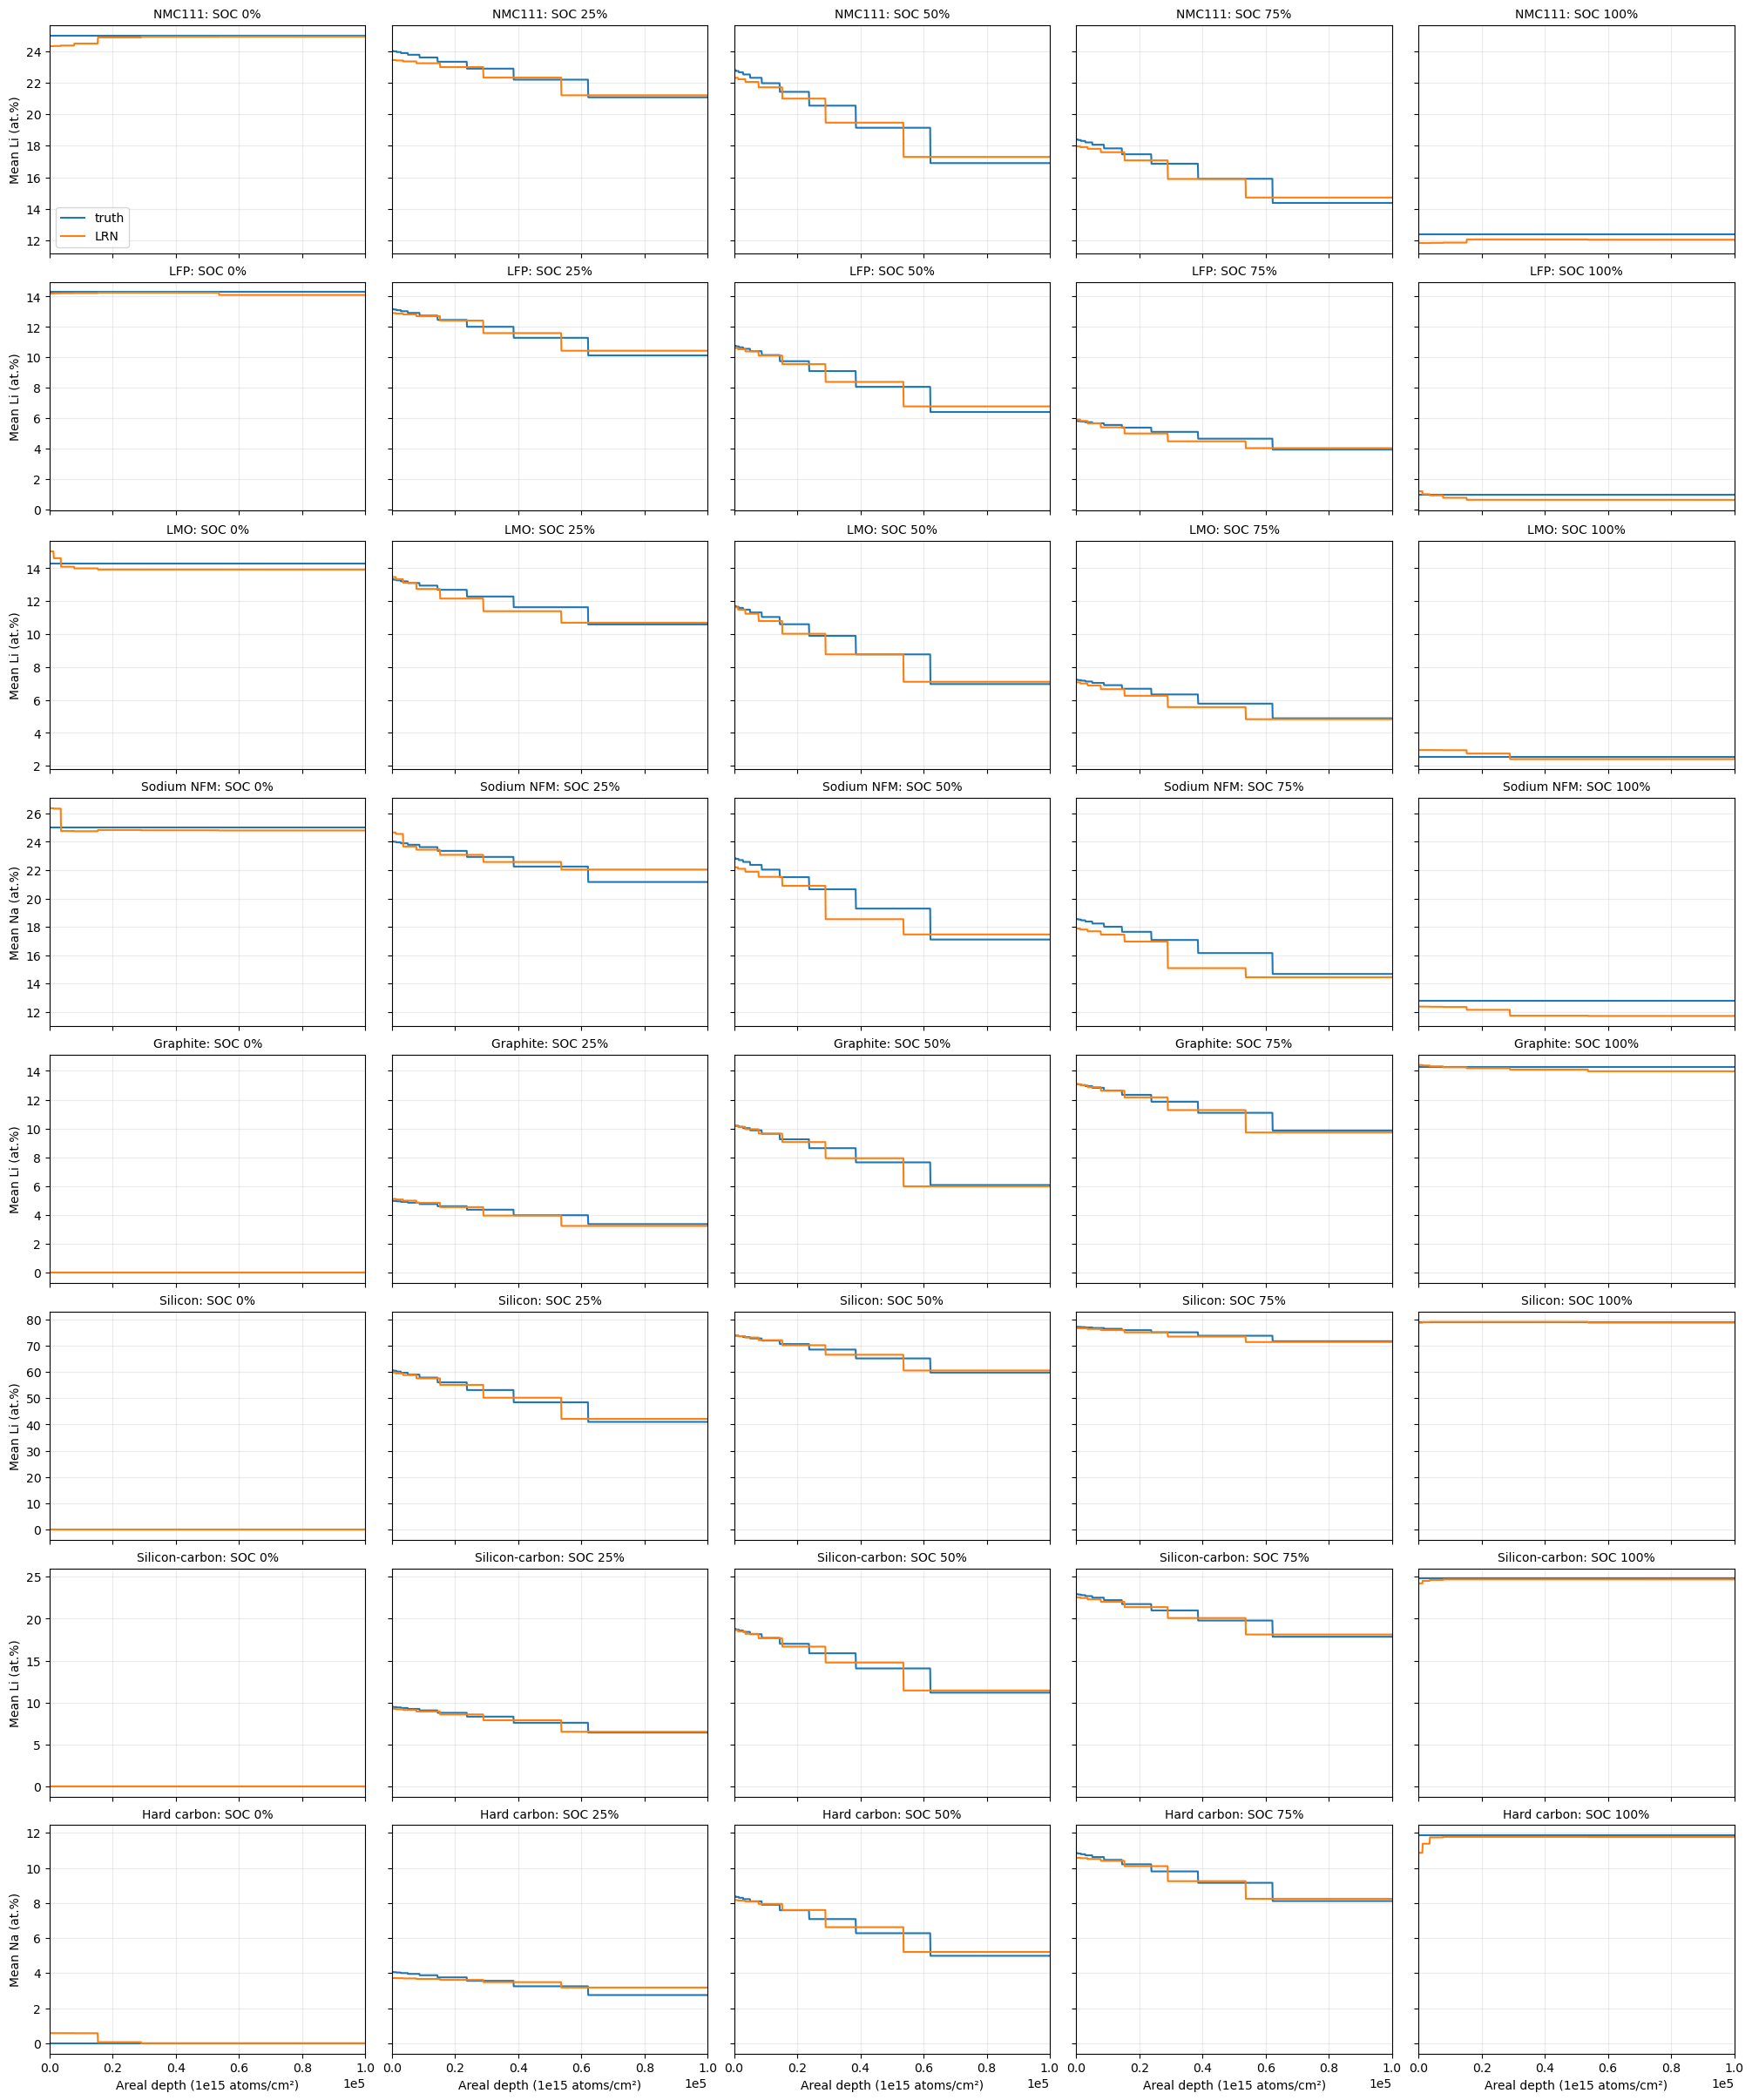

In [17]:
depth_grid=np.linspace(0,TMAX,int(round(TMAX/DEPTH_STEP))+1)
mean_profiles, depth_rows, thickness_rows = {}, [], []
for cell in cells:
    indices=groups[cell["cell_id"]]
    chem=scan.CHEMISTRY_BY_NAME[cell["chemistry"]]
    ion_index=elements.index(chem.mobile_ion)
    for method in ("truth","LRN"):
        summed=np.zeros(len(depth_grid))
        totals=[]
        for i in indices:
            edges,f=(truth_edges,truth_stacks[i]) if method=="truth" else (fits[names[i]]["edges"],fits[names[i]]["fractions"])
            summed += sample_stack(edges,f[:,ion_index:ion_index+1],depth_grid)[:,0]
            totals.append(edges[-1])
        average=summed/len(indices)
        totals=np.array(totals)
        extended=np.mean(depth_grid[None,:]>totals[:,None],axis=0)
        mean_profiles[(cell["cell_id"],method)]=average
        thickness_rows.append(dict(cell_id=cell["cell_id"],chemistry=chem.name,method=method,
            minimum=float(totals.min()),mean=float(totals.mean()),maximum=float(totals.max()),
            positions_below_tmax=int(np.sum(totals<TMAX))))
        for z,f,ex in zip(depth_grid,average,extended):
            depth_rows.append(dict(cell_id=cell["cell_id"],chemistry=chem.name,mobile_ion=chem.mobile_ion,
                nominal_soc_pct=100*cell["soc"],method=method,depth_1e15_atoms_cm2=float(z),
                mean_atomic_fraction=float(f),extrapolated_positions_fraction=float(ex)))
write_csv("cell_mobile_ion_depth_profiles.csv",depth_rows)
write_csv("cell_profile_thickness.csv",thickness_rows)

fig,axes=plt.subplots(8,5,figsize=(20,24),sharex=True,sharey="row",constrained_layout=True)
for cell in cells:
    ax=axes[cell["row"],cell["column"]]
    chem=scan.CHEMISTRY_BY_NAME[cell["chemistry"]]
    for method in ("truth","LRN"):
        ax.plot(depth_grid,100*mean_profiles[(cell["cell_id"],method)],label=method)
    ax.set_title(f"{chem.name}: SOC {100*cell['soc']:.0f}%",fontsize=10)
    ax.set_xlim(0,TMAX)
    ax.grid(alpha=.25)
    ax.ticklabel_format(axis="x",style="sci",scilimits=(0,0))
    if cell["column"]==0:
        ax.set_ylabel(f"Mean {chem.mobile_ion} (at.%)")
    if cell["row"]==7:
        ax.set_xlabel("Areal depth (1e15 atoms/cm²)")
axes[0,0].legend()
finish(fig,"cell_mobile_ion_depth_profiles")


## Elemental maps at a selected depth

Set `HEATMAP_DEPTH` in the first code cell, then rerun this cell. Compare truth, LRN and their difference for each element over the full raster, including Al holder. This uses the discretized layer stacks. Internal boundaries choose the deeper sublayer. With `EXTEND_LAST=False`, positions beyond profile thickness are masked; otherwise the last concentration is held. Each element uses a common truth/LRN color scale; its error panel uses a symmetric scale.


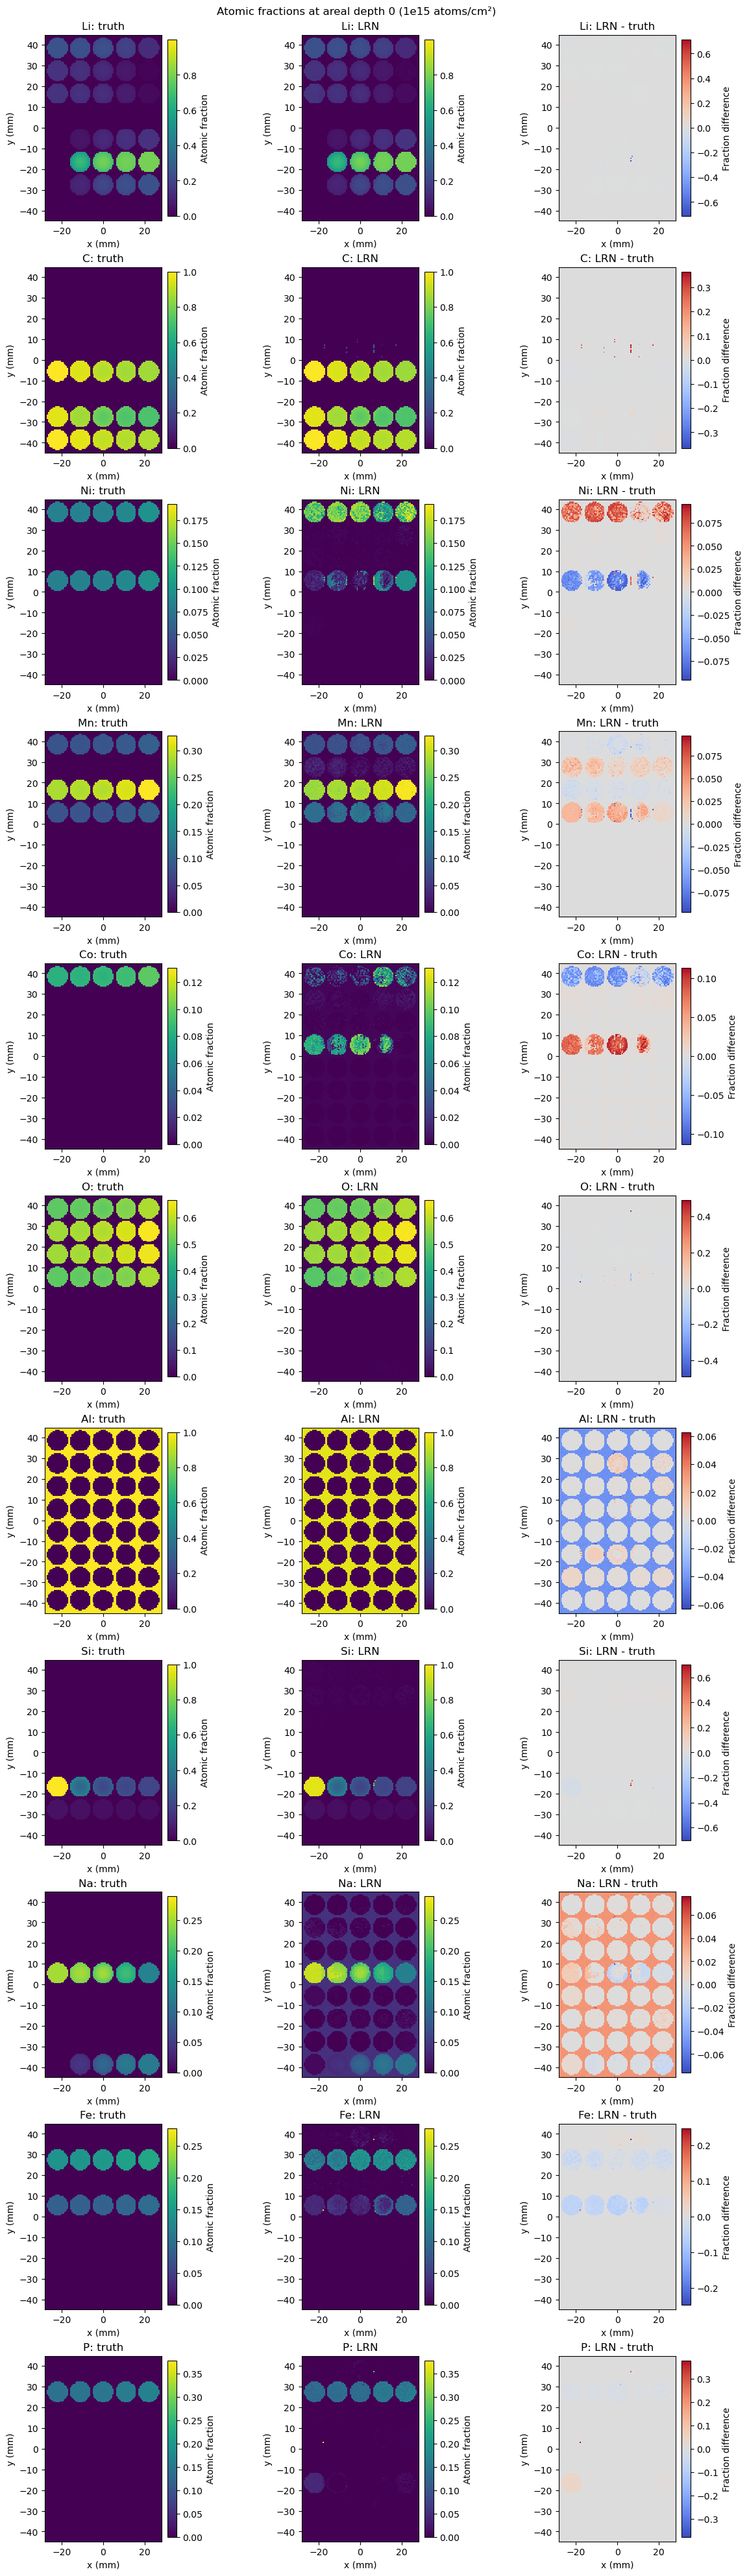

Positions beyond truth/LRN thickness: [0 0]
Comparison exports: d:\ibeamlab\examples\datasets\Batt\LRN_comparison


In [18]:
if not np.isfinite(HEATMAP_DEPTH) or HEATMAP_DEPTH<0:
    raise ValueError("HEATMAP_DEPTH must be finite and nonnegative")
map_truth=np.full((len(names),len(elements)),np.nan)
map_fit=np.full_like(map_truth,np.nan)
covered=np.zeros((len(names),2),bool)
for i,name in enumerate(names):
    for k,(edges,f,target) in enumerate(((truth_edges,truth_stacks[i],map_truth),
                                       (fits[name]["edges"],fits[name]["fractions"],map_fit))):
        covered[i,k]=HEATMAP_DEPTH<=edges[-1]
        if covered[i,k] or EXTEND_LAST:
            target[i]=sample_stack(edges,f,[HEATMAP_DEPTH])[0]
for a in (map_truth,map_fit):
    valid=np.isfinite(a).all(axis=1)
    np.testing.assert_allclose(a[valid].sum(axis=1),1,atol=1e-12)
fig,axes=plt.subplots(len(elements),3,figsize=(12,3.6*len(elements)),constrained_layout=True)
for j,e in enumerate(elements):
    vmax=max(float(np.nanmax(np.r_[map_truth[:,j],map_fit[:,j]])),1e-6) if np.isfinite(map_truth[:,j]).any() else 1
    difference=map_fit[:,j]-map_truth[:,j]
    limit=max(float(np.nanmax(abs(difference))),1e-6) if np.isfinite(difference).any() else 1
    for ax,values,title in zip(axes[j,:2],(map_truth[:,j],map_fit[:,j]),("truth","LRN")):
        m=spatial_image(ax,values,f"{e}: {title}",vmin=0,vmax=vmax)
        fig.colorbar(m,ax=ax,label="Atomic fraction",fraction=.046,pad=.03)
    m=spatial_image(axes[j,2],difference,f"{e}: LRN - truth",cmap="coolwarm",vmin=-limit,vmax=limit)
    fig.colorbar(m,ax=axes[j,2],label="Fraction difference",fraction=.046,pad=.03)
fig.suptitle(f"Atomic fractions at areal depth {HEATMAP_DEPTH:g} (1e15 atoms/cm²)")
tag=f"{HEATMAP_DEPTH:g}".replace(".","p")
finish(fig,f"element_heatmaps_depth_{tag}")
np.savez_compressed(OUT/f"element_heatmaps_depth_{tag}.npz",xy_mm=xy,elements=np.array(elements),
    truth=map_truth,LRN=map_fit,depth=HEATMAP_DEPTH,covered=covered,extend_last=EXTEND_LAST)
print("Positions beyond truth/LRN thickness:",np.sum(~covered,axis=0))
print("Comparison exports:",OUT)
